# Imports

In [574]:
import os
import random
import torch
import torch.nn as nn
import numpy as np
from typing import List
import matplotlib.pyplot as plt
from PIL import Image, ImageChops, ImageFilter, ImageEnhance

torch.manual_seed(67)

# Data Processing

### Loading

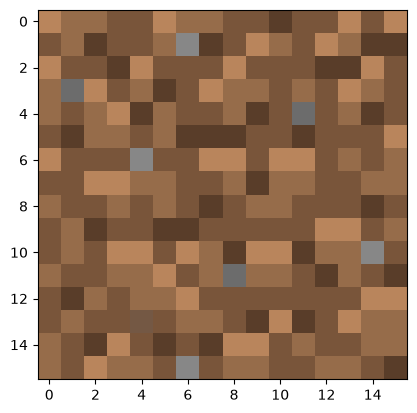

In [36]:
classes = [i for i in filter(lambda x: os.path.isdir(f"./dataset/{x}"), os.listdir("./dataset"))]

blocks = {k:[] for k in classes}
for k in blocks.keys():
    for img in os.listdir(f"./dataset/{k}"):
        blocks[k].append(f"./dataset/{k}/{img}")

plt.imshow( plt.imread(blocks['dirt'][5]) )

Препроцессинг данных я проводил на этапе создания датасета.

Поскольку датасет очень маленький я создам функцию для аугментации изображения:

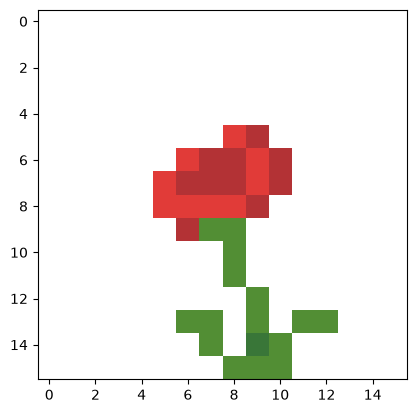

In [571]:
def Augment(input):
    img = Image.fromarray((input * 255).astype(np.uint8))
    
    img = img.transpose(Image.FLIP_LEFT_RIGHT) if random.random() > 0.5 else img

    img = img.rotate(random.gauss(mu=0, sigma=0.5) * 15)
    # img = img.filter(ImageFilter.GaussianBlur(random.random() * 1))
    img = ImageEnhance.Brightness(img).enhance(1 + random.random()/2 - 0.25 )
    img = ImageEnhance.Contrast(img).enhance(1 + random.random()/2 - 0.25 )
    img = ImageEnhance.Color(img).enhance(1 + random.random()/2 - 0.25 )
    img = np.array(img.convert("RGBA"))

    # noise = np.random.normal(0, 5, [16,16,1])
    # img[:,:,:3] = np.clip(img[:,:,:3] + noise, 0, 255).astype(np.uint8)


    return img

test = Augment(plt.imread(blocks['flower'][1]))
plt.imshow(test)

# Model

In [719]:
class MLP(nn.Module):
    def __init__(self, inShape: List[int] = [16,16,4], hiddenShape: List[int] = [32, 64, 128, 64, 32], outSize:int = 5):
        super().__init__()

        
        self.layers = nn.Sequential(
            nn.Linear(inShape[0]*inShape[1]*inShape[2], hiddenShape[0]),
            nn.Tanh()
        )
        for i in range(len(hiddenShape)-1):
            self.layers.append( nn.Linear(hiddenShape[i], hiddenShape[i+1]) )
            self.layers.append( nn.Tanh() )

        
        self.layers.append( nn.Linear(hiddenShape[-1], outSize) )

        
    def forward(self, x):
        return self.layers(x)

model = MLP(hiddenShape=[128, 128, 128, 128])

In [716]:
x_train, y_train = [], []
x_val, y_val = [], []
x_test, y_test = [], []

for k in blocks.keys():
    class_idx = list(blocks.keys()).index(k)
    for i, v in enumerate(blocks[k]):
        if i < 4:
            x_train.append(v)
            y_train.append(torch.tensor([class_idx], dtype=torch.long))
        elif i < 6:
            x_val.append(v)
            y_val.append(torch.tensor([class_idx], dtype=torch.long))
        else:
            x_test.append(v)
            y_test.append(torch.tensor([class_idx], dtype=torch.long))

In [717]:
def prepare(img_path, augment=False):
    img = Augment(plt.imread(img_path)) if augment else plt.imread(img_path)
    img = torch.from_numpy(img).float() / 255.0 if augment else torch.from_numpy(img)
    img = img.flatten().unsqueeze(0)
    
    return img

In [720]:
optimizer = torch.optim.Adam(model.parameters())
crossEntropy = nn.CrossEntropyLoss()

for i in range(1000):
    total_loss = 0
    for x, y in zip(x_train, y_train):

        optimizer.zero_grad()
        
        
        pred = model( prepare(x, augment=True) )
        loss = crossEntropy(pred, y)
        total_loss += loss

        loss.backward()

        optimizer.step()
    
    if (i % 50) == 0:
        print(total_loss)

tensor(41.9335, grad_fn=<AddBackward0>)
tensor(21.7487, grad_fn=<AddBackward0>)
tensor(23.7598, grad_fn=<AddBackward0>)
tensor(22.8572, grad_fn=<AddBackward0>)
tensor(20.5001, grad_fn=<AddBackward0>)
tensor(23.1446, grad_fn=<AddBackward0>)
tensor(23.6903, grad_fn=<AddBackward0>)


KeyboardInterrupt: 

In [723]:
model( prepare(x_val[1]) )

tensor([[ 1.3396, -6.6746, -1.6246,  1.3624,  0.8726]],
       grad_fn=<AddmmBackward0>)

In [ ]:
import os
import random
import torch
import torch.nn as nn
import numpy as np
from typing import List
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance

torch.manual_seed(67)
np.random.seed(67)
random.seed(67)

# ================= 1. ЗАГРУЗКА ДАННЫХ =================
classes = [i for i in filter(lambda x: os.path.isdir(f"./dataset/{x}"), os.listdir("./dataset"))]

blocks = {k:[] for k in classes}
for k in blocks.keys():
    for img in os.listdir(f"./dataset/{k}"):
        blocks[k].append(f"./dataset/{k}/{img}")

# ================= 2. АУГМЕНТАЦИЯ =================
def Augment(input_np):
    # Безопасное преобразование в uint8
    if input_np.dtype == np.float32 or input_np.dtype == np.float64:
        img = Image.fromarray((input_np * 255).astype(np.uint8))
    else:
        img = Image.fromarray(input_np.astype(np.uint8))
    
    # 1. Отражение (безопасно для 16x16)
    if random.random() > 0.5:
        img = img.transpose(Image.FLIP_LEFT_RIGHT)

    # 2. ЦВЕТОВЫЕ ИСКАЖЕНИЯ (безопасно для 16x16)
    # Значения от 0.75 до 1.25
    factor = 1 + random.random()/2 - 0.25
    img = ImageEnhance.Brightness(img).enhance(factor)
    
    factor = 1 + random.random()/2 - 0.25
    img = ImageEnhance.Contrast(img).enhance(factor)
    
    factor = 1 + random.random()/2 - 0.25
    img = ImageEnhance.Color(img).enhance(factor)

    # 3. ЛЕГКИЙ СДВИГ (заменяем опасный rotate)
    # Сдвигаем на 1 пиксель по горизонтали и вертикали
    tx = random.randint(-1, 1)
    ty = random.randint(-1, 1)
    img_array = np.array(img)
    img_array = np.roll(img_array, shift=(ty, tx), axis=(0, 1)) # Безопасный сдвиг без черных краев

    return img_array.astype(np.uint8)

# ================= 3. МОДЕЛЬ =================
class MLP(nn.Module):
    def __init__(self, inShape: List[int] = [16,16,4], hiddenShape: List[int] = [128, 128, 128, 128], outSize:int = 5):
        super().__init__()
        
        self.layers = nn.Sequential(
            nn.Flatten(), # Автоматически делает из (1, 16, 16, 4) -> (1, 1024)
            nn.Linear(inShape[0]*inShape[1]*inShape[2], hiddenShape[0]),
            nn.ReLU(),    # ИСПРАВЛЕНИЕ: Заменяем Tanh на ReLU
            # nn.Dropout(0.2) # ИСПРАВЛЕНИЕ: Добавляем Dropout от переобучения
        )
        
        for i in range(len(hiddenShape)-1):
            self.layers.append(nn.Linear(hiddenShape[i], hiddenShape[i+1]))
            self.layers.append(nn.ReLU())
            # self.layers.append(nn.Dropout(0.2))
            
        self.layers.append(nn.Linear(hiddenShape[-1], outSize))

    def forward(self, x):
        return self.layers(x)

model = MLP(hiddenShape=[128, 256, 256, 128])

# ================= 4. ПОДГОТОВКА ДАННЫХ =================
def prepare(img_path, augment=False):
    # ИСПРАВЛЕНИЕ: Используем PIL для гарантированного получения 4 каналов (RGBA)
    img = Image.open(img_path).convert("RGBA")
    
    if augment:
        img = Image.fromarray(Augment(np.array(img)))
    
    # ИСПРАВЛЕНИЕ: Всегда нормализуем в [0.0, 1.0]
    img_np = np.array(img).astype(np.float32) / 255.0
    
    # Превращаем в тензор и добавляем батч: (16, 16, 4) -> (1, 16, 16, 4)
    return torch.from_numpy(img_np).unsqueeze(0)

# ================= 5. РАЗДЕЛЕНИЕ ДАННЫХ =================
x_train, y_train = [], []
x_val, y_val = [], []
x_test, y_test = [], []

for k in blocks.keys():
    class_idx = list(blocks.keys()).index(k)
    for i, v in enumerate(blocks[k]):
        if i < 4:
            x_train.append(v)
            y_train.append(torch.tensor(class_idx, dtype=torch.long)) # (1,) -> () скаляр
        elif i < 6:
            x_val.append(v)
            y_val.append(torch.tensor(class_idx, dtype=torch.long))
        else:
            x_test.append(v)
            y_test.append(torch.tensor(class_idx, dtype=torch.long))

# ================= 6. ОБУЧЕНИЕ =================
optimizer = torch.optim.Adam(model.parameters(), lr=0.000314) # Явно задали скорость обучения
crossEntropy = nn.CrossEntropyLoss()

num_classes = len(classes)

for epoch in range(1000): # 200 эпох достаточно для старта
    model.train()
    total_loss = 0
    correct_train = 0
    
    # Перемешиваем данные каждую эпоху (очень важно для малых датасетов)
    indices = list(range(len(x_train)))
    random.shuffle(indices)
    
    for idx in indices:
        x = x_train[idx]
        y = y_train[idx]
        
        optimizer.zero_grad()
        
        pred = model(prepare(x, augment=True))
        loss = crossEntropy(pred, y.unsqueeze(0)) # y должен быть (1,)
        
        total_loss += loss.item() # ИСПРАВЛЕНИЕ: .item() предотвращает утечку памяти
        
        loss.backward()
        optimizer.step()
        
        # Считаем точность
        if pred.argmax(dim=1).item() == y.item():
            correct_train += 1
            
    # ================= 7. ВАЛИДАЦИЯ =================
    model.eval()
    correct_val = 0
    with torch.no_grad(): # Отключаем градиенты для экономии памяти
        for x, y in zip(x_val, y_val):
            pred = model(prepare(x, augment=False))
            if pred.argmax(dim=1).item() == y.item():
                correct_val += 1
                
    if epoch % 20 == 0:
        train_acc = correct_train / len(x_train) * 100
        val_acc = correct_val / len(x_val) * 100
        print(f"Epoch {epoch:03d} | Loss: {total_loss/len(x_train):.4f} | Train Acc: {train_acc:.1f}% | Val Acc: {val_acc:.1f}%")

# ================= 8. ФИНАЛЬНЫЙ ТЕСТ =================
model.eval()
print("\n--- Финальная проверка на случайном объекте из валидации ---")
with torch.no_grad():
    test_img_path = x_val[0]
    pred = model(prepare(test_img_path, augment=False))
    predicted_class_idx = pred.argmax(dim=1).item()
    true_class_idx = y_val[0].item()
    
    print(f"Истинный класс: {classes[true_class_idx]}")
    print(f"Предсказанный класс: {classes[predicted_class_idx]}")
    print(f"Вероятности (софтмакс): {torch.softmax(pred, dim=1).numpy()}")

Epoch 000 | Loss: 1.6178 | Train Acc: 10.0% | Val Acc: 20.0%
Epoch 020 | Loss: 1.1255 | Train Acc: 45.0% | Val Acc: 40.0%
Epoch 040 | Loss: 1.0878 | Train Acc: 50.0% | Val Acc: 60.0%
Epoch 060 | Loss: 0.7146 | Train Acc: 60.0% | Val Acc: 60.0%
Epoch 080 | Loss: 0.7816 | Train Acc: 60.0% | Val Acc: 80.0%
Epoch 100 | Loss: 0.5258 | Train Acc: 70.0% | Val Acc: 60.0%
Epoch 120 | Loss: 0.5598 | Train Acc: 75.0% | Val Acc: 90.0%
Epoch 140 | Loss: 0.7212 | Train Acc: 65.0% | Val Acc: 80.0%
Epoch 160 | Loss: 0.5724 | Train Acc: 70.0% | Val Acc: 60.0%
Epoch 180 | Loss: 0.6016 | Train Acc: 60.0% | Val Acc: 70.0%
Epoch 200 | Loss: 0.4845 | Train Acc: 80.0% | Val Acc: 80.0%
Epoch 220 | Loss: 0.6436 | Train Acc: 65.0% | Val Acc: 100.0%
Epoch 240 | Loss: 0.5709 | Train Acc: 75.0% | Val Acc: 70.0%
Epoch 260 | Loss: 0.4805 | Train Acc: 75.0% | Val Acc: 100.0%
Epoch 280 | Loss: 0.4586 | Train Acc: 80.0% | Val Acc: 90.0%
Epoch 300 | Loss: 0.3515 | Train Acc: 85.0% | Val Acc: 70.0%
Epoch 320 | Loss: 0.51

In [779]:
pred = model(prepare('Sprite-0001.png', augment=False))
predicted_class_idx = pred.argmax(dim=1).item()
classes[predicted_class_idx], pred

('planks',
 tensor([[ -9.2387, -12.6570,  -6.1401, -22.8431,   2.6693]],
        grad_fn=<AddmmBackward0>))